In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from src.models.churn_models import load_data, logistic_model, BASE_FEATURES

sns.set_theme(style="whitegrid")
data = load_data()

# Final model: trained on all 16 labeled snapshots (Jun 2010 to Sep 2011)
model = logistic_model().fit(data[BASE_FEATURES], data["churned"])
prep, clf = model[:-1], model[-1]
X = pd.DataFrame(prep.transform(data[BASE_FEATURES]), columns=BASE_FEATURES, index=data.index)

explainer = shap.LinearExplainer(clf, X)
values = explainer.shap_values(X)
print(values.shape)

Background dataset has 47933 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=47933 when initializing the masker.


(47933, 16)


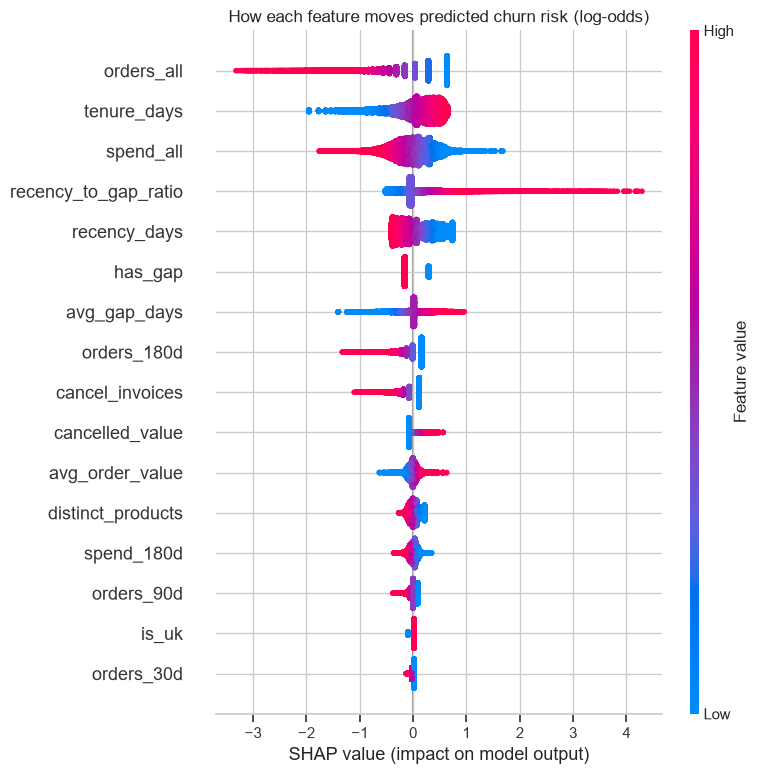

orders_all              0.485
tenure_days             0.343
spend_all               0.289
recency_to_gap_ratio    0.267
recency_days            0.228
has_gap                 0.194
avg_gap_days            0.192
orders_180d             0.159
cancel_invoices         0.150
cancelled_value         0.104
avg_order_value         0.070
distinct_products       0.063
spend_180d              0.057
orders_90d              0.047
is_uk                   0.024
orders_30d              0.020
dtype: float64

In [2]:
shap.summary_plot(values, X, show=False)
plt.title("How each feature moves predicted churn risk (log-odds)")
plt.tight_layout()
plt.show()

importance = pd.Series(np.abs(values).mean(axis=0), index=BASE_FEATURES).sort_values(ascending=False)
importance.round(3)

In [3]:
latest = data["snapshot_date"] == data["snapshot_date"].max()
scores = pd.Series(model.predict_proba(data.loc[latest, BASE_FEATURES])[:, 1], index=data.index[latest])

for label, i in [("Highest risk", scores.idxmax()), ("Lowest risk", scores.idxmin())]:
    pos = data.index.get_loc(i)
    contrib = pd.Series(values[pos], index=BASE_FEATURES).sort_values(key=np.abs, ascending=False).head(5)
    print(f"\n{label}: customer_key={data.loc[i, 'customer_key']}, predicted risk {scores[i]:.2f}, actually churned={data.loc[i, 'churned']}")
    print(contrib.round(2).to_string())


Highest risk: customer_key=2885, predicted risk 0.94, actually churned=1
recency_to_gap_ratio    4.06
avg_gap_days           -1.40
recency_days           -0.34
orders_all              0.28
spend_all               0.20

Lowest risk: customer_key=2566, predicted risk 0.00, actually churned=0
orders_all        -3.32
spend_all         -1.54
orders_180d       -1.22
cancel_invoices   -1.11
avg_gap_days      -1.09


## Findings
- Model explained: the logistic regression trained on all 16 labeled snapshots. SHAP values are in log-odds on standardized, signed-log features.
- Most influential features (mean absolute SHAP): orders_all (0.49), tenure_days (0.34), spend_all (0.29), recency_to_gap_ratio (0.27), recency_days (0.23).
- Customers with more orders, higher spend and more orders in the last 180 days get lower risk. Customers with only one purchase day (has_gap = 0) get higher risk.
- A high recency_to_gap_ratio (overdue relative to the customer's own usual gap) produces the largest upward push in risk.
- Several features move together (orders_all, tenure_days, recency_days, recency_to_gap_ratio, avg_gap_days), so a single feature's sign depends on the others. Longer tenure raising risk and larger recency_days lowering it is opposite to intuition and is best read as part of one combined purchase-rhythm signal.
- SHAP describes how the model uses its inputs. It does not show that any feature causes a customer to leave.